# Final Comparison of Emotion Recognition Models
- Baseline CNN
- EfficientNetB0
- MobileNetV2

In [1]:
# Load Data
import numpy as np

X_test = np.load("X_test.npy")
y_test = np.load("y_test.npy")

# Convert grayscale → RGB for transfer learning models
X_test_rgb = np.repeat(X_test, 3, axis=-1)

In [2]:
# Load Models
import tensorflow as tf

cnn_model = tf.keras.models.load_model("models/emotion_model.keras")
efficientnet_model = tf.keras.models.load_model("models/emotion_efficientnet.keras")
mobilenet_model = tf.keras.models.load_model("models/emotion_mobilenet.keras")

In [3]:
# Evaluation Function
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

emotions = ['angry','disgust','fear','happy','neutral','sad','surprise']

def evaluate_model(model, X, y, title="Model"):
    y_pred = model.predict(X)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y, axis=1)

    # Confusion Matrix
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=emotions, yticklabels=emotions)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix - {title}")
    plt.show()

    # Classification Report
    print(f"Classification Report - {title}")
    print(classification_report(y_true_classes, y_pred_classes, target_names=emotions))

    # Accuracy
    acc = accuracy_score(y_true_classes, y_pred_classes)
    return acc

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


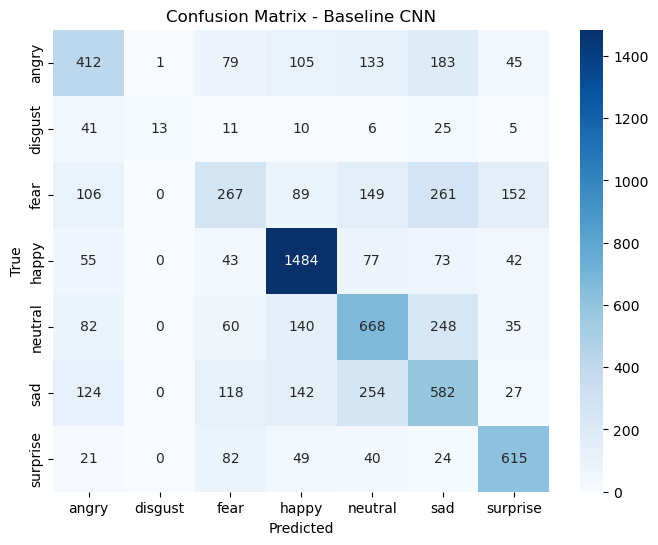

Classification Report - Baseline CNN
              precision    recall  f1-score   support

       angry       0.49      0.43      0.46       958
     disgust       0.93      0.12      0.21       111
        fear       0.40      0.26      0.32      1024
       happy       0.74      0.84      0.78      1774
     neutral       0.50      0.54      0.52      1233
         sad       0.42      0.47      0.44      1247
    surprise       0.67      0.74      0.70       831

    accuracy                           0.56      7178
   macro avg       0.59      0.48      0.49      7178
weighted avg       0.56      0.56      0.55      7178

225/225 ━━━━━━━━━━━━━━━━━━━━ 14s 54ms/step


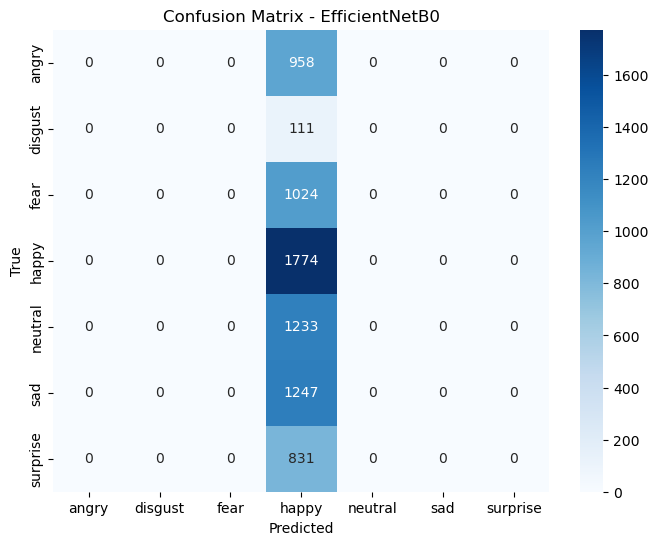

Classification Report - EfficientNetB0
              precision    recall  f1-score   support

       angry       0.00      0.00      0.00       958
     disgust       0.00      0.00      0.00       111
        fear       0.00      0.00      0.00      1024
       happy       0.25      1.00      0.40      1774
     neutral       0.00      0.00      0.00      1233
         sad       0.00      0.00      0.00      1247
    surprise       0.00      0.00      0.00       831

    accuracy                           0.25      7178
   macro avg       0.04      0.14      0.06      7178
weighted avg       0.06      0.25      0.10      7178



d:\Anaconda\envs\fer_new\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Anaconda\envs\fer_new\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Anaconda\envs\fer_new\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


225/225 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step


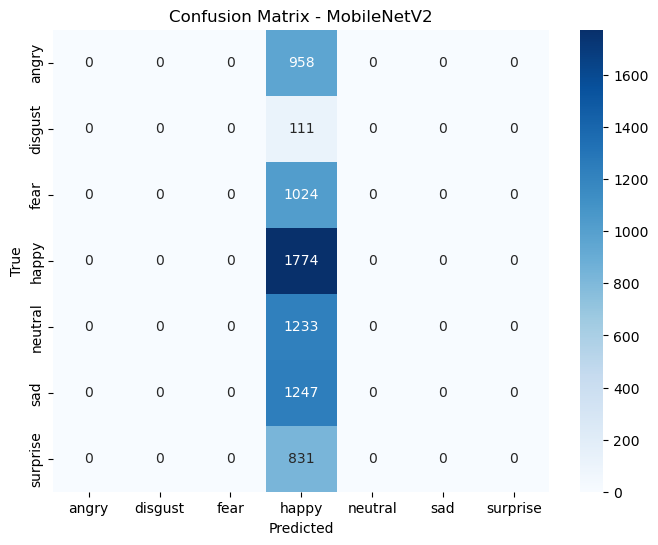

Classification Report - MobileNetV2
              precision    recall  f1-score   support

       angry       0.00      0.00      0.00       958
     disgust       0.00      0.00      0.00       111
        fear       0.00      0.00      0.00      1024
       happy       0.25      1.00      0.40      1774
     neutral       0.00      0.00      0.00      1233
         sad       0.00      0.00      0.00      1247
    surprise       0.00      0.00      0.00       831

    accuracy                           0.25      7178
   macro avg       0.04      0.14      0.06      7178
weighted avg       0.06      0.25      0.10      7178



d:\Anaconda\envs\fer_new\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Anaconda\envs\fer_new\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Anaconda\envs\fer_new\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [4]:
# Run Evaluations
acc_cnn = evaluate_model(cnn_model, X_test, y_test, "Baseline CNN")
acc_efficientnet = evaluate_model(efficientnet_model, X_test_rgb, y_test, "EfficientNetB0")
acc_mobilenet = evaluate_model(mobilenet_model, X_test_rgb, y_test, "MobileNetV2")

In [5]:
# Comparison Table
import pandas as pd

results = pd.DataFrame({
    "Model": ["Baseline CNN", "EfficientNetB0", "MobileNetV2"],
    "Accuracy": [acc_cnn, acc_efficientnet, acc_mobilenet]
})

print(results)

            Model  Accuracy
0    Baseline CNN  0.562970
1  EfficientNetB0  0.247144
2     MobileNetV2  0.247144
